# Notebook 07 – ResNet-18 Transfer Learning for CamVid Multi-Label Scene Classification

**Project:** AI-Powered Smart Road Intelligence and Traffic Safety Monitoring System  
**Scene classification and transfer learning**  
**Dataset:** CamVid  
**Purpose:** Train an ImageNet-pretrained ResNet-18 to predict which semantic classes are present in each CamVid image.

## Why this notebook exists

This notebook complements the earlier baseline CNN classification experiment. It uses transfer learning rather than training the complete feature extractor from scratch. The task is **multi-label image classification**: one image can contain several classes (for example, Road, Building, Car, Sky and Pedestrian).

The labels are read from the image-level class-presence columns in the preprocessing metadata. This notebook does not train a pixel-wise segmentation model; segmentation is covered separately.

## Metadata files supplied for this project

Use the master file as the single source of truth:

- `preprocessed/camvid_preprocessed_metadata.csv` – all 701 records, including the `split` column.
- `preprocessed/train_metadata.csv` – 406 training records.
- `preprocessed/validation_metadata.csv` – 171 validation records.
- `preprocessed/test_metadata.csv` – 124 test records.

The master file already contains the split assignment. Therefore, this notebook **does not create a new random split** and does not need to concatenate the three split-specific CSVs.

The supplied metadata contains 31 candidate class columns. `Train` and `Tunnel` have zero positive examples in the complete 701-image dataset, so they cannot be learned or meaningfully evaluated. They are excluded, leaving **29 supported class targets**.

## 1. Environment and imports

The notebook is designed for a PyTorch environment. In Google Colab, mount Google Drive before running the path configuration cell if your dataset is stored there.

If PyTorch / torchvision are not installed or are incompatible, install a mutually compatible pair in the runtime before continuing. Avoid upgrading one without checking the other.

In [1]:
# Optional Google Colab setup:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
import random
import time
import copy
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights

from sklearn.metrics import (
    accuracy_score,
    hamming_loss,
    precision_recall_fscore_support,
    classification_report,
    multilabel_confusion_matrix,
)

warnings.filterwarnings("ignore", category=UserWarning)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
CUDA available: True


## 2. Reproducibility and configuration

Update only the paths if your notebook is stored in a different directory.

- `METADATA_PATH` should point to the **master** `camvid_preprocessed_metadata.csv`.
- `IMAGE_ROOT` should normally remain `None` when the paths stored in `image_path` are accessible.
- If the CSV contains Google Drive paths that do not resolve in your runtime, set `IMAGE_ROOT` to the actual CamVid `images` directory. When set, this directory is used with each row's `filename`, overriding the stored absolute path.

In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

CAM_VID_ROOT = Path("/content/drive/MyDrive/AAI-521/project/datasets/camvid")
# Adjust relative to the directory from which this notebook is executed.
METADATA_PATH = CAM_VID_ROOT  / "preprocessed/camvid_preprocessed_metadata.csv"

# Leave as None to use the CSV's image_path values.
IMAGE_ROOT = CAM_VID_ROOT / "images"

OUTPUT_DIR = CAM_VID_ROOT / "outputs/notebook_07_resnet18_transfer_learning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0  # Safer default across Colab, Windows and notebook environments

HEAD_EPOCHS = 8
FINETUNE_EPOCHS = 22
PATIENCE = 5

DROPOUT = 0.4
HEAD_LR = 1e-3
FINETUNE_LR = 1e-4
WEIGHT_DECAY = 1e-4
THRESHOLD = 0.5

# True downloads/uses ImageNet pretrained weights.
# Set False only if pretrained weights cannot be downloaded or accessed.
USE_IMAGENET_WEIGHTS = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"Metadata CSV not found: {METADATA_PATH.resolve()}\n"
        "Update METADATA_PATH to the location of preprocessed/camvid_preprocessed_metadata.csv."
    )

print("Metadata:", METADATA_PATH.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("Device:", DEVICE)

Metadata: /content/drive/MyDrive/AAI-521/project/datasets/camvid/preprocessed/camvid_preprocessed_metadata.csv
Output directory: /content/drive/MyDrive/AAI-521/project/datasets/camvid/outputs/notebook_07_resnet18_transfer_learning
Device: cuda


## 3. Load and validate the supplied master metadata

The supplied metadata schema includes these important fields:

- `filename`: image identifier without the file extension.
- `image`: image file path (also present as `image_path`).
- `image_path`: image file path used by the Dataset.
- `mask` / `mask_path`: corresponding segmentation-mask path; not used as a model input here.
- `sequence_id`: source video sequence.
- `split`: `train`, `validation` or `test`.
- 31 binary image-level class-presence columns.

The code below excludes metadata/path fields, validates the binary targets, removes only classes with no positive examples anywhere in the dataset, and verifies that the resulting 29 targets are supported.

In [4]:
df = pd.read_csv(METADATA_PATH)

print("Master metadata shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

required_columns = {"filename", "split"}
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

# The uploaded CSV contains both image and image_path. Prefer image_path.
if "image_path" not in df.columns:
    if "image" in df.columns:
        df["image_path"] = df["image"]
    else:
        raise ValueError(
            "Neither image_path nor image is present. "
            "Provide an image path column or configure IMAGE_ROOT."
        )

# These are metadata / path / bookkeeping columns, not prediction targets.
NON_TARGET_COLUMNS = {
    "image", "filename", "mask",
    "number_of_classes", "sequence_id", "split",
    "image_path", "mask_path", "image_exists", "mask_exists",
}

candidate_class_columns = [
    col for col in df.columns if col not in NON_TARGET_COLUMNS
]

# Validate that candidate class columns are numeric binary labels.
for col in candidate_class_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    if df[col].isna().any():
        raise ValueError(f"Class column {col!r} contains missing/non-numeric values.")
    values = set(df[col].unique())
    if not values.issubset({0, 1}):
        raise ValueError(f"Class column {col!r} is not binary: {sorted(values)}")

class_support = df[candidate_class_columns].sum().astype(int)
zero_support_classes = class_support[class_support == 0].index.tolist()
class_columns = [
    col for col in candidate_class_columns
    if class_support[col] > 0
]

print("\nCandidate class columns:", len(candidate_class_columns))
print("Zero-support classes excluded:", zero_support_classes)
print("Supported target classes:", len(class_columns))
print(class_columns)

if len(candidate_class_columns) != 31:
    raise ValueError(
        f"Expected 31 candidate class columns from the supplied metadata, "
        f"found {len(candidate_class_columns)}. Review the metadata schema."
    )

if set(zero_support_classes) != {"Train", "Tunnel"}:
    raise ValueError(
        "The zero-support classes differ from the supplied metadata expectation. "
        f"Observed: {zero_support_classes}"
    )

if len(class_columns) != 29:
    raise ValueError(f"Expected 29 supported classes after exclusions, found {len(class_columns)}.")

# Normalize split names but preserve the existing partition assignments.
df["split"] = df["split"].astype(str).str.strip().str.lower()
split_aliases = {
    "train": "train",
    "training": "train",
    "val": "val",
    "valid": "val",
    "validation": "val",
    "test": "test",
    "testing": "test",
}
df["split"] = df["split"].map(lambda value: split_aliases.get(value, value))

if df["split"].isna().any():
    raise ValueError("Unrecognized or missing split values were found.")

expected_split_counts = {"train": 406, "val": 171, "test": 124}
observed_split_counts = df["split"].value_counts().to_dict()
print("\nObserved split counts:", observed_split_counts)

if observed_split_counts != expected_split_counts:
    raise ValueError(
        f"Split counts differ from the supplied metadata: {observed_split_counts}. "
        f"Expected: {expected_split_counts}"
    )

if df["filename"].duplicated().any():
    duplicates = df.loc[df["filename"].duplicated(), "filename"].tolist()
    raise ValueError(f"Duplicate filenames found: {duplicates[:10]}")

print("\nClass support across all 701 images:")
display(class_support.sort_values(ascending=False).to_frame("positive_images"))

Master metadata shape: (701, 41)
Columns:
['image', 'filename', 'mask', 'Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCone', 'TrafficLight', 'Train', 'Tree', 'Truck_Bus', 'Tunnel', 'VegetationMisc', 'Wall', 'number_of_classes', 'sequence_id', 'split', 'image_path', 'mask_path', 'image_exists', 'mask_exists']

Candidate class columns: 31
Zero-support classes excluded: ['Train', 'Tunnel']
Supported target classes: 29
['Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCo

,positive_images
Road,701
Sky,699
Column_Pole,699
LaneMkgsDriv,696
Building,687
Sidewalk,672
Car,643
Pedestrian,640
Tree,637
Misc_Text,599


## 4. Resolve image paths and verify dataset integrity

The uploaded metadata stores absolute Google Drive paths in `image_path`. These paths are valid only when the same Drive location is mounted in the current runtime.

The path resolver supports two modes:

1. `IMAGE_ROOT = None`: use each row's stored `image_path`.
2. `IMAGE_ROOT` is set: use `IMAGE_ROOT / filename` for every image.

The notebook intentionally fails with a useful error if image files cannot be found. It does not silently discard records, because doing so would change the established train/validation/test split.

In [5]:
def resolve_image_path(row):
    filename = str(row["filename"])
    # Preserve an extension if filename already has one; otherwise use the
    # basename of the stored image path to recover the original image filename.
    stored_path = str(row["image_path"])
    stored_name = Path(stored_path).name

    if IMAGE_ROOT is not None:
        candidate = Path(IMAGE_ROOT) / stored_name
    else:
        candidate = Path(stored_path)

    return str(candidate)

df["resolved_image_path"] = df.apply(resolve_image_path, axis=1)

missing_image_mask = ~df["resolved_image_path"].apply(lambda p: Path(p).is_file())
missing_images = df.loc[missing_image_mask, ["filename", "resolved_image_path"]]

print("Total records:", len(df))
print("Images found:", int((~missing_image_mask).sum()))
print("Images missing:", int(missing_image_mask.sum()))

if not missing_images.empty:
    display(missing_images.head(15))
    raise FileNotFoundError(
        "Some image files could not be found. If the CSV paths refer to Google Drive, "
        "mount Drive and confirm the path. Alternatively, set IMAGE_ROOT to the actual "
        "CamVid images directory."
    )

print("Image-path validation: PASS")

Total records: 701
Images found: 701
Images missing: 0
Image-path validation: PASS


## 5. Validate split integrity and inspect label distribution

The supplied split assignment is retained. `sequence_id` is checked to ensure that a source video sequence does not appear in more than one partition. This is important because adjacent frames from the same sequence are visually similar and could otherwise cause data leakage.

Records per split:


,images
split,
train,406
val,171
test,124


Sequence-level split integrity: PASS
Unique sequences by split:


,unique_sequences
split,
test,1
train,2
val,1


,train,val,test
Animal,4,22,0
Archway,99,8,0
Bicyclist,241,48,75
Bridge,10,0,0
Building,395,168,124
Car,358,161,124
CartLuggagePram,154,28,59
Child,132,22,0
Column_Pole,405,171,123
Fence,261,62,41


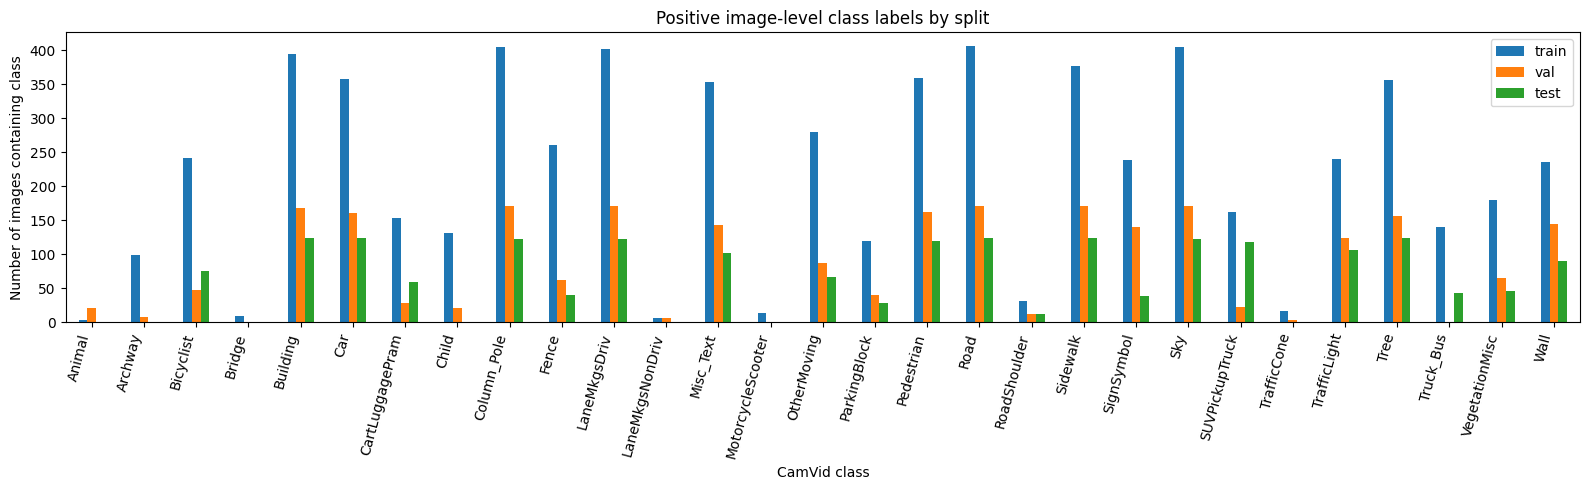

In [6]:
print("Records per split:")
display(df["split"].value_counts().rename_axis("split").to_frame("images"))

if "sequence_id" in df.columns:
    sequence_sets = {
        split: set(group["sequence_id"].dropna().astype(str))
        for split, group in df.groupby("split")
    }

    overlaps = []
    split_names = list(sequence_sets)
    for i, split_a in enumerate(split_names):
        for split_b in split_names[i + 1:]:
            common = sequence_sets[split_a] & sequence_sets[split_b]
            if common:
                overlaps.append((split_a, split_b, sorted(common)))

    if overlaps:
        raise ValueError(f"Sequence leakage detected: {overlaps}")

    print("Sequence-level split integrity: PASS")
    print("Unique sequences by split:")
    display(
        df.groupby("split")["sequence_id"]
        .nunique()
        .rename("unique_sequences")
        .to_frame()
    )

distribution = pd.DataFrame({
    split: df.loc[df["split"] == split, class_columns].sum()
    for split in ["train", "val", "test"]
})

display(distribution)

ax = distribution.plot(kind="bar", figsize=(16, 5))
ax.set_title("Positive image-level class labels by split")
ax.set_xlabel("CamVid class")
ax.set_ylabel("Number of images containing class")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 6. Build the PyTorch Dataset and DataLoaders

ResNet-18 expects three-channel RGB images. Inputs are resized to 224 × 224 and normalized using ImageNet statistics.

Training augmentation is intentionally lightweight: random horizontal flipping and mild color jitter. Validation and test images receive deterministic resizing and normalization only. Labels are the 29 binary image-level class-presence values from the metadata.

In [7]:
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])


class CamVidMultiLabelDataset(Dataset):
    def __init__(self, frame, class_names, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.class_names = list(class_names)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["resolved_image_path"]) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        labels = torch.tensor(
            row[self.class_names].to_numpy(dtype=np.float32),
            dtype=torch.float32,
        )

        return image, labels, str(row["filename"])


train_df = df[df["split"] == "train"].copy().reset_index(drop=True)
val_df = df[df["split"] == "val"].copy().reset_index(drop=True)
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

train_dataset = CamVidMultiLabelDataset(train_df, class_columns, train_transform)
val_dataset = CamVidMultiLabelDataset(val_df, class_columns, eval_transform)
test_dataset = CamVidMultiLabelDataset(test_df, class_columns, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

images, labels, filenames = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Example filenames:", list(filenames[:3]))

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.shape[1] == len(class_columns) == 29

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16, 29])
Example filenames: ['0006R0_f03690', '0016E5_07991', '0016E5_06630']


## 7. Visualize a few training examples and their labels

This is a sanity check that the image files and metadata labels are paired correctly. The displayed labels are image-level presence labels, not pixel-level segmentation annotations.

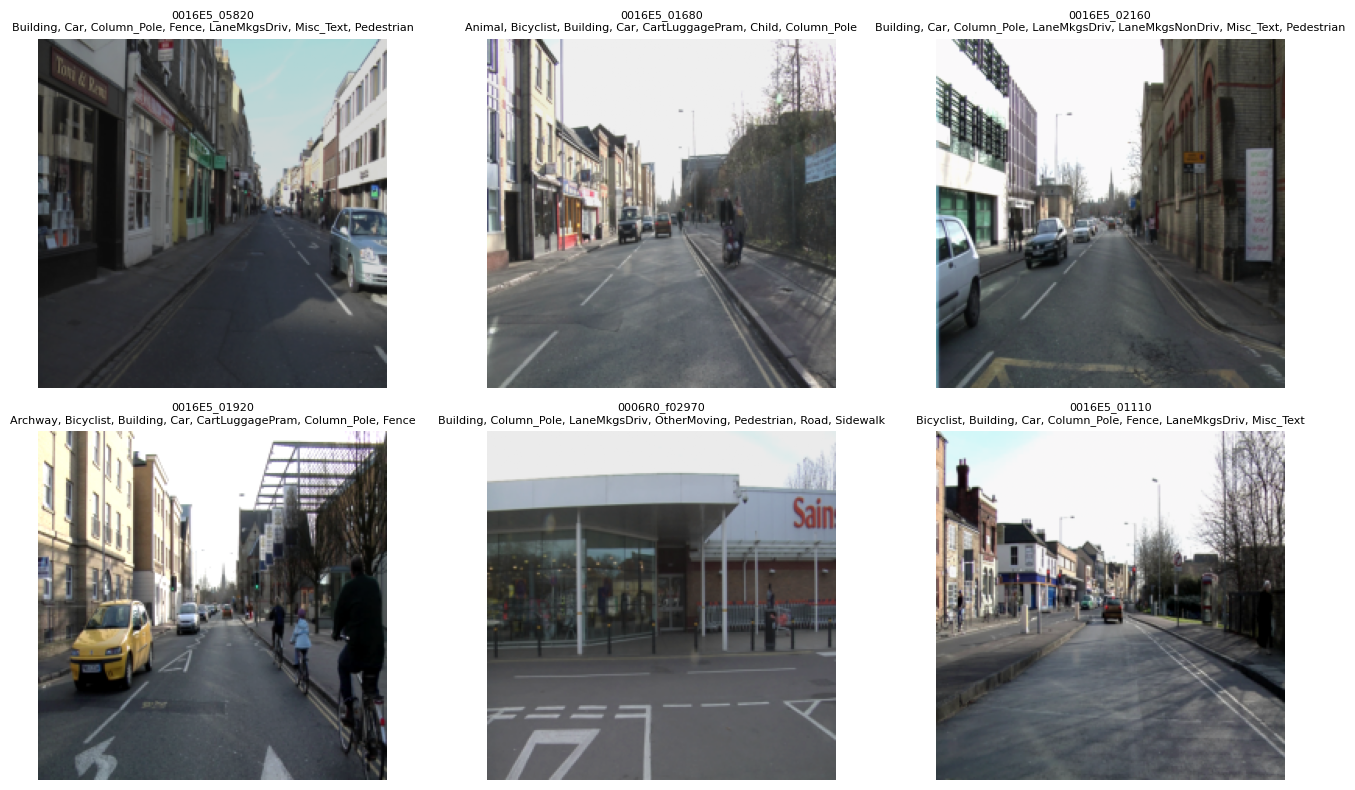

In [8]:
def denormalize_image(tensor):
    mean = torch.tensor(imagenet_mean).view(3, 1, 1)
    std = torch.tensor(imagenet_std).view(3, 1, 1)
    return (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

sample_images, sample_labels, sample_names = next(iter(train_loader))
sample_count = min(6, len(sample_names))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, image_tensor, label_vector, name in zip(
    axes.flat,
    sample_images[:sample_count],
    sample_labels[:sample_count],
    sample_names[:sample_count],
):
    ax.imshow(denormalize_image(image_tensor))
    present = [
        class_columns[i]
        for i, value in enumerate(label_vector.tolist())
        if value == 1
    ]
    ax.set_title(f"{name}\n{', '.join(present[:7])}", fontsize=8)
    ax.axis("off")

for ax in axes.flat[sample_count:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Create the ImageNet-pretrained ResNet-18 model

The original 1,000-class ImageNet fully connected layer is replaced by a 29-output classification head. Since an image can contain multiple classes simultaneously, the model returns logits and uses `BCEWithLogitsLoss`; sigmoid is applied only when converting logits into probabilities for evaluation.

In [9]:
if USE_IMAGENET_WEIGHTS:
    weights = ResNet18_Weights.DEFAULT
else:
    weights = None

model = models.resnet18(weights=weights)
in_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(p=DROPOUT),
    nn.Linear(in_features, len(class_columns)),
)

model = model.to(DEVICE)
criterion = nn.BCEWithLogitsLoss()


def freeze_backbone(model):
    for name, parameter in model.named_parameters():
        parameter.requires_grad = name.startswith("fc.")


def unfreeze_layer4_and_head(model):
    for name, parameter in model.named_parameters():
        parameter.requires_grad = (
            name.startswith("layer4.") or name.startswith("fc.")
        )


freeze_backbone(model)

print(model)
print(
    "Trainable parameters in head-training stage:",
    sum(p.numel() for p in model.parameters() if p.requires_grad),
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 9. Training and prediction utilities

The validation loss is used for checkpoint selection and early stopping. The test set is not used during training or model selection.

Batch-normalization layers are kept in evaluation mode during training so that their pretrained running statistics are not destabilized by the relatively small CamVid batches.

In [10]:
def run_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    if is_training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

    running_loss = 0.0
    total_samples = 0

    for batch_images, targets, _ in loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(batch_images)
            loss = criterion(logits, targets)

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = batch_images.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

    return running_loss / max(total_samples, 1)


def predict_loader(model, loader):
    model.eval()
    all_targets, all_probabilities, all_filenames = [], [], []

    with torch.no_grad():
        for batch_images, targets, filenames in loader:
            batch_images = batch_images.to(DEVICE, non_blocking=True)
            logits = model(batch_images)
            probabilities = torch.sigmoid(logits).cpu().numpy()

            all_probabilities.append(probabilities)
            all_targets.append(targets.numpy())
            all_filenames.extend(list(filenames))

    return (
        np.concatenate(all_targets, axis=0),
        np.concatenate(all_probabilities, axis=0),
        all_filenames,
    )


def fit_stage(
    model,
    train_loader,
    val_loader,
    epochs,
    learning_rate,
    stage_name,
):
    trainable_parameters = [
        parameter for parameter in model.parameters()
        if parameter.requires_grad
    ]

    optimizer = torch.optim.Adam(
        trainable_parameters,
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
    )

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    stage_history = []

    for epoch in range(1, epochs + 1):
        start_time = time.time()

        train_loss = run_epoch(model, train_loader, optimizer)
        val_loss = run_epoch(model, val_loader, optimizer=None)
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        stage_history.append({
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "learning_rate": current_lr,
        })

        print(
            f"{stage_name} | Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"lr={current_lr:.2e} | "
            f"time={time.time() - start_time:.1f}s"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
            torch.save(
                best_state,
                OUTPUT_DIR / f"best_{stage_name}.pth",
            )
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping: validation loss did not improve for "
                f"{PATIENCE} consecutive epochs."
            )
            break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(stage_history), best_val_loss

## 10. Stage 1 – train the new classification head

Freeze the ResNet-18 feature extractor and train only the new 29-class output head. This allows the classifier to adapt to CamVid while preserving the pretrained ImageNet features.

In [11]:
model, history_head, best_head_val_loss = fit_stage(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=HEAD_EPOCHS,
    learning_rate=HEAD_LR,
    stage_name="head",
)

print("Best Stage 1 validation loss:", round(best_head_val_loss, 5))

head | Epoch 01/8 | train_loss=0.4446 | val_loss=0.3751 | lr=1.00e-03 | time=451.4s
head | Epoch 02/8 | train_loss=0.3556 | val_loss=0.3605 | lr=1.00e-03 | time=26.5s
head | Epoch 03/8 | train_loss=0.3187 | val_loss=0.3665 | lr=1.00e-03 | time=26.9s
head | Epoch 04/8 | train_loss=0.2983 | val_loss=0.3641 | lr=1.00e-03 | time=26.0s
head | Epoch 05/8 | train_loss=0.2820 | val_loss=0.3763 | lr=5.00e-04 | time=26.2s
head | Epoch 06/8 | train_loss=0.2694 | val_loss=0.3657 | lr=5.00e-04 | time=25.5s
head | Epoch 07/8 | train_loss=0.2667 | val_loss=0.3620 | lr=5.00e-04 | time=26.3s
Early stopping: validation loss did not improve for 5 consecutive epochs.
Best Stage 1 validation loss: 0.36045


## 11. Stage 2 – fine-tune the final ResNet block

Unfreeze `layer4` and the classification head. Earlier convolutional blocks remain frozen. Fine-tuning uses a smaller learning rate to make controlled adjustments to the pretrained high-level features.

In [12]:
unfreeze_layer4_and_head(model)

print(
    "Trainable parameters in fine-tuning stage:",
    sum(p.numel() for p in model.parameters() if p.requires_grad),
)

model, history_finetune, best_finetune_val_loss = fit_stage(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=FINETUNE_EPOCHS,
    learning_rate=FINETUNE_LR,
    stage_name="finetune",
)

history = pd.concat(
    [history_head, history_finetune],
    ignore_index=True,
)
history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print("Best Stage 2 validation loss:", round(best_finetune_val_loss, 5))

Trainable parameters in fine-tuning stage: 8408605
finetune | Epoch 01/22 | train_loss=0.2883 | val_loss=0.3978 | lr=1.00e-04 | time=26.9s
finetune | Epoch 02/22 | train_loss=0.2194 | val_loss=0.4056 | lr=1.00e-04 | time=26.0s
finetune | Epoch 03/22 | train_loss=0.1891 | val_loss=0.4336 | lr=1.00e-04 | time=26.3s
finetune | Epoch 04/22 | train_loss=0.1663 | val_loss=0.4171 | lr=5.00e-05 | time=26.7s
finetune | Epoch 05/22 | train_loss=0.1387 | val_loss=0.4866 | lr=5.00e-05 | time=26.8s
finetune | Epoch 06/22 | train_loss=0.1227 | val_loss=0.4452 | lr=5.00e-05 | time=26.5s
Early stopping: validation loss did not improve for 5 consecutive epochs.
Best Stage 2 validation loss: 0.39777


## 12. Plot training and validation loss

Use the curves to assess convergence and overfitting. A persistent increase in validation loss while training loss decreases suggests overfitting. The best checkpoint for each stage is selected using validation loss.

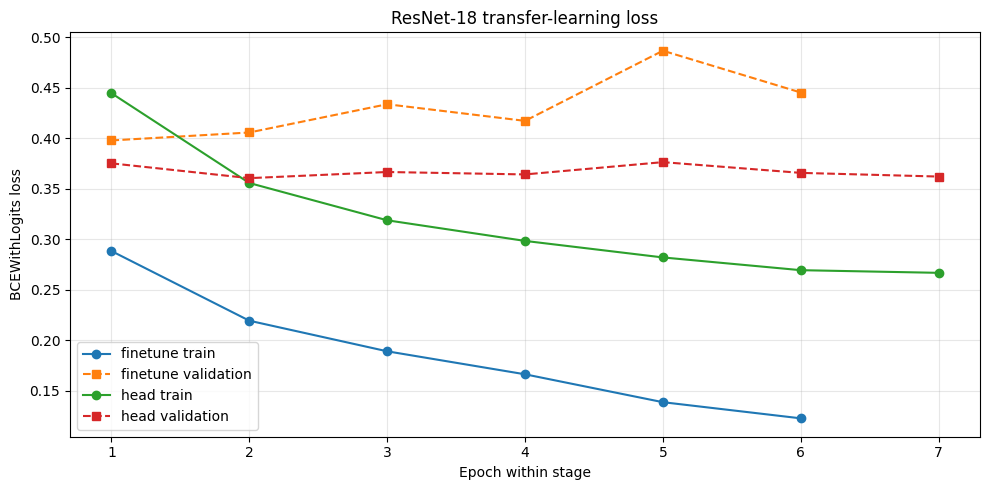

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

for stage_name, stage_data in history.groupby("stage"):
    ax.plot(
        stage_data["epoch"],
        stage_data["train_loss"],
        marker="o",
        label=f"{stage_name} train",
    )
    ax.plot(
        stage_data["epoch"],
        stage_data["val_loss"],
        marker="s",
        linestyle="--",
        label=f"{stage_name} validation",
    )

ax.set_title("ResNet-18 transfer-learning loss")
ax.set_xlabel("Epoch within stage")
ax.set_ylabel("BCEWithLogits loss")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 13. Define multi-label evaluation metrics

At the default threshold of 0.5, each class probability is converted into a binary prediction. Report micro, macro and weighted precision/recall/F1, exact-match accuracy and Hamming loss.

- **Micro F1** aggregates decisions across all labels and is influenced by common classes.
- **Macro F1** gives equal weight to each class and exposes performance on rare classes.
- **Exact-match accuracy** requires all labels for an image to be correct.
- **Hamming loss** measures the fraction of individual label decisions that are incorrect.

In [14]:
def calculate_multilabel_metrics(y_true, y_prob, threshold=THRESHOLD):
    y_pred = (y_prob >= threshold).astype(int)

    micro = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0
    )
    macro = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    summary = {
        "threshold": float(threshold),
        "micro_precision": float(micro[0]),
        "micro_recall": float(micro[1]),
        "micro_f1": float(micro[2]),
        "macro_precision": float(macro[0]),
        "macro_recall": float(macro[1]),
        "macro_f1": float(macro[2]),
        "weighted_precision": float(weighted[0]),
        "weighted_recall": float(weighted[1]),
        "weighted_f1": float(weighted[2]),
        "exact_match_accuracy": float(accuracy_score(y_true, y_pred)),
        "hamming_loss": float(hamming_loss(y_true, y_pred)),
    }

    per_class = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0
    )

    per_class_df = pd.DataFrame({
        "class": class_columns,
        "precision": per_class[0],
        "recall": per_class[1],
        "f1_score": per_class[2],
        "support": per_class[3],
    }).sort_values("f1_score", ascending=False)

    return summary, per_class_df, y_pred

## 14. Validation-set evaluation

Evaluate the selected fine-tuned model on the validation partition. Use these results for model diagnostics, not as the final reported test performance.

In [15]:
y_val, val_probabilities, val_filenames = predict_loader(model, val_loader)

val_summary, val_per_class, val_predictions = calculate_multilabel_metrics(
    y_val,
    val_probabilities,
)

print("Validation summary (threshold = 0.5)")
display(pd.DataFrame([val_summary]).T.rename(columns={0: "validation"}))
display(val_per_class)

val_per_class.to_csv(
    OUTPUT_DIR / "validation_per_class_metrics.csv",
    index=False,
)
with open(OUTPUT_DIR / "validation_summary_metrics.json", "w") as file:
    json.dump(val_summary, file, indent=2)

Validation summary (threshold = 0.5)


,validation
threshold,0.500000
micro_precision,0.815126
micro_recall,0.860137
micro_f1,0.837027
macro_precision,0.496068
macro_recall,0.532737
macro_f1,0.489400
weighted_precision,0.827302
weighted_recall,0.860137
weighted_f1,0.825850


,class,precision,recall,f1_score,support
8,Column_Pole,1.000000,1.000000,1.000000,171
10,LaneMkgsDriv,1.000000,1.000000,1.000000,171
21,Sky,1.000000,1.000000,1.000000,171
17,Road,1.000000,1.000000,1.000000,171
19,Sidewalk,1.000000,1.000000,1.000000,171
4,Building,0.982456,1.000000,0.991150,168
16,Pedestrian,0.947368,1.000000,0.972973,162
5,Car,0.941520,1.000000,0.969880,161
25,Tree,0.912281,1.000000,0.954128,156
12,Misc_Text,0.836257,1.000000,0.910828,143


## 15. Validation per-class F1 and confusion matrices

Each target is a separate binary classification problem. The multi-label confusion matrix therefore contains one 2 × 2 matrix per class (true negative, false positive, false negative and true positive).

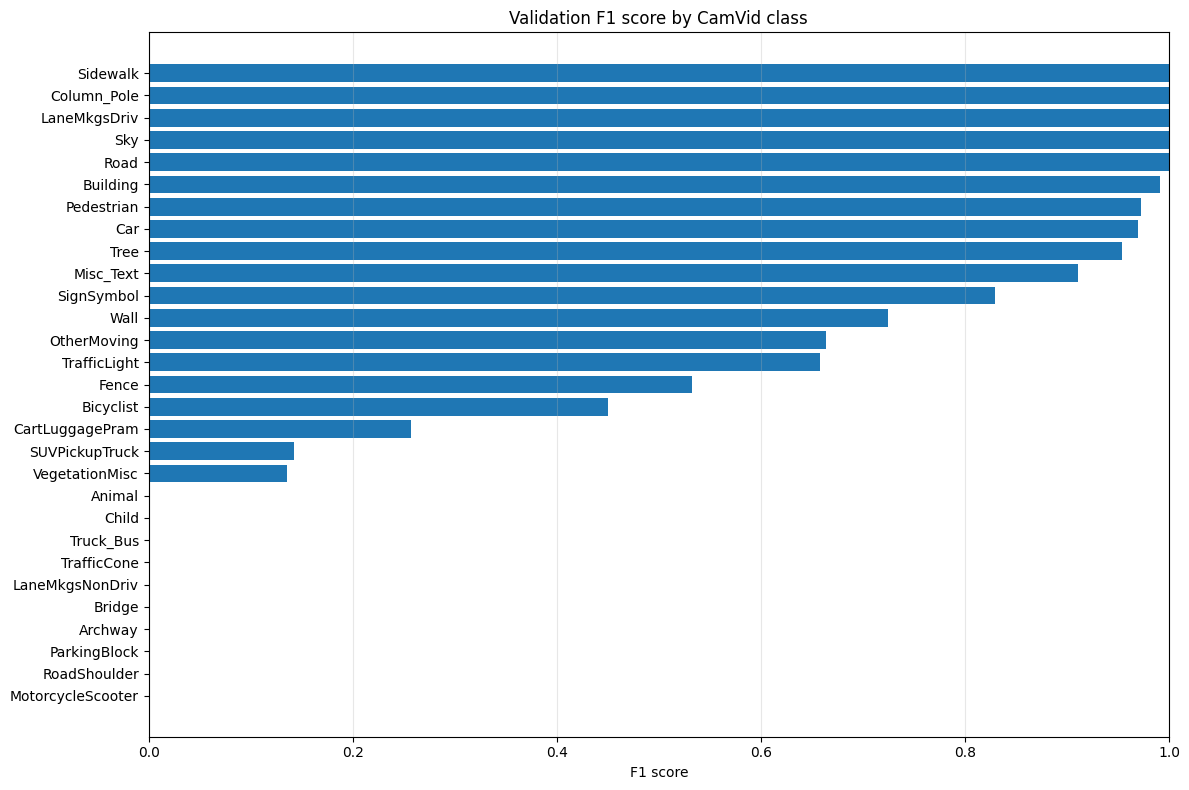

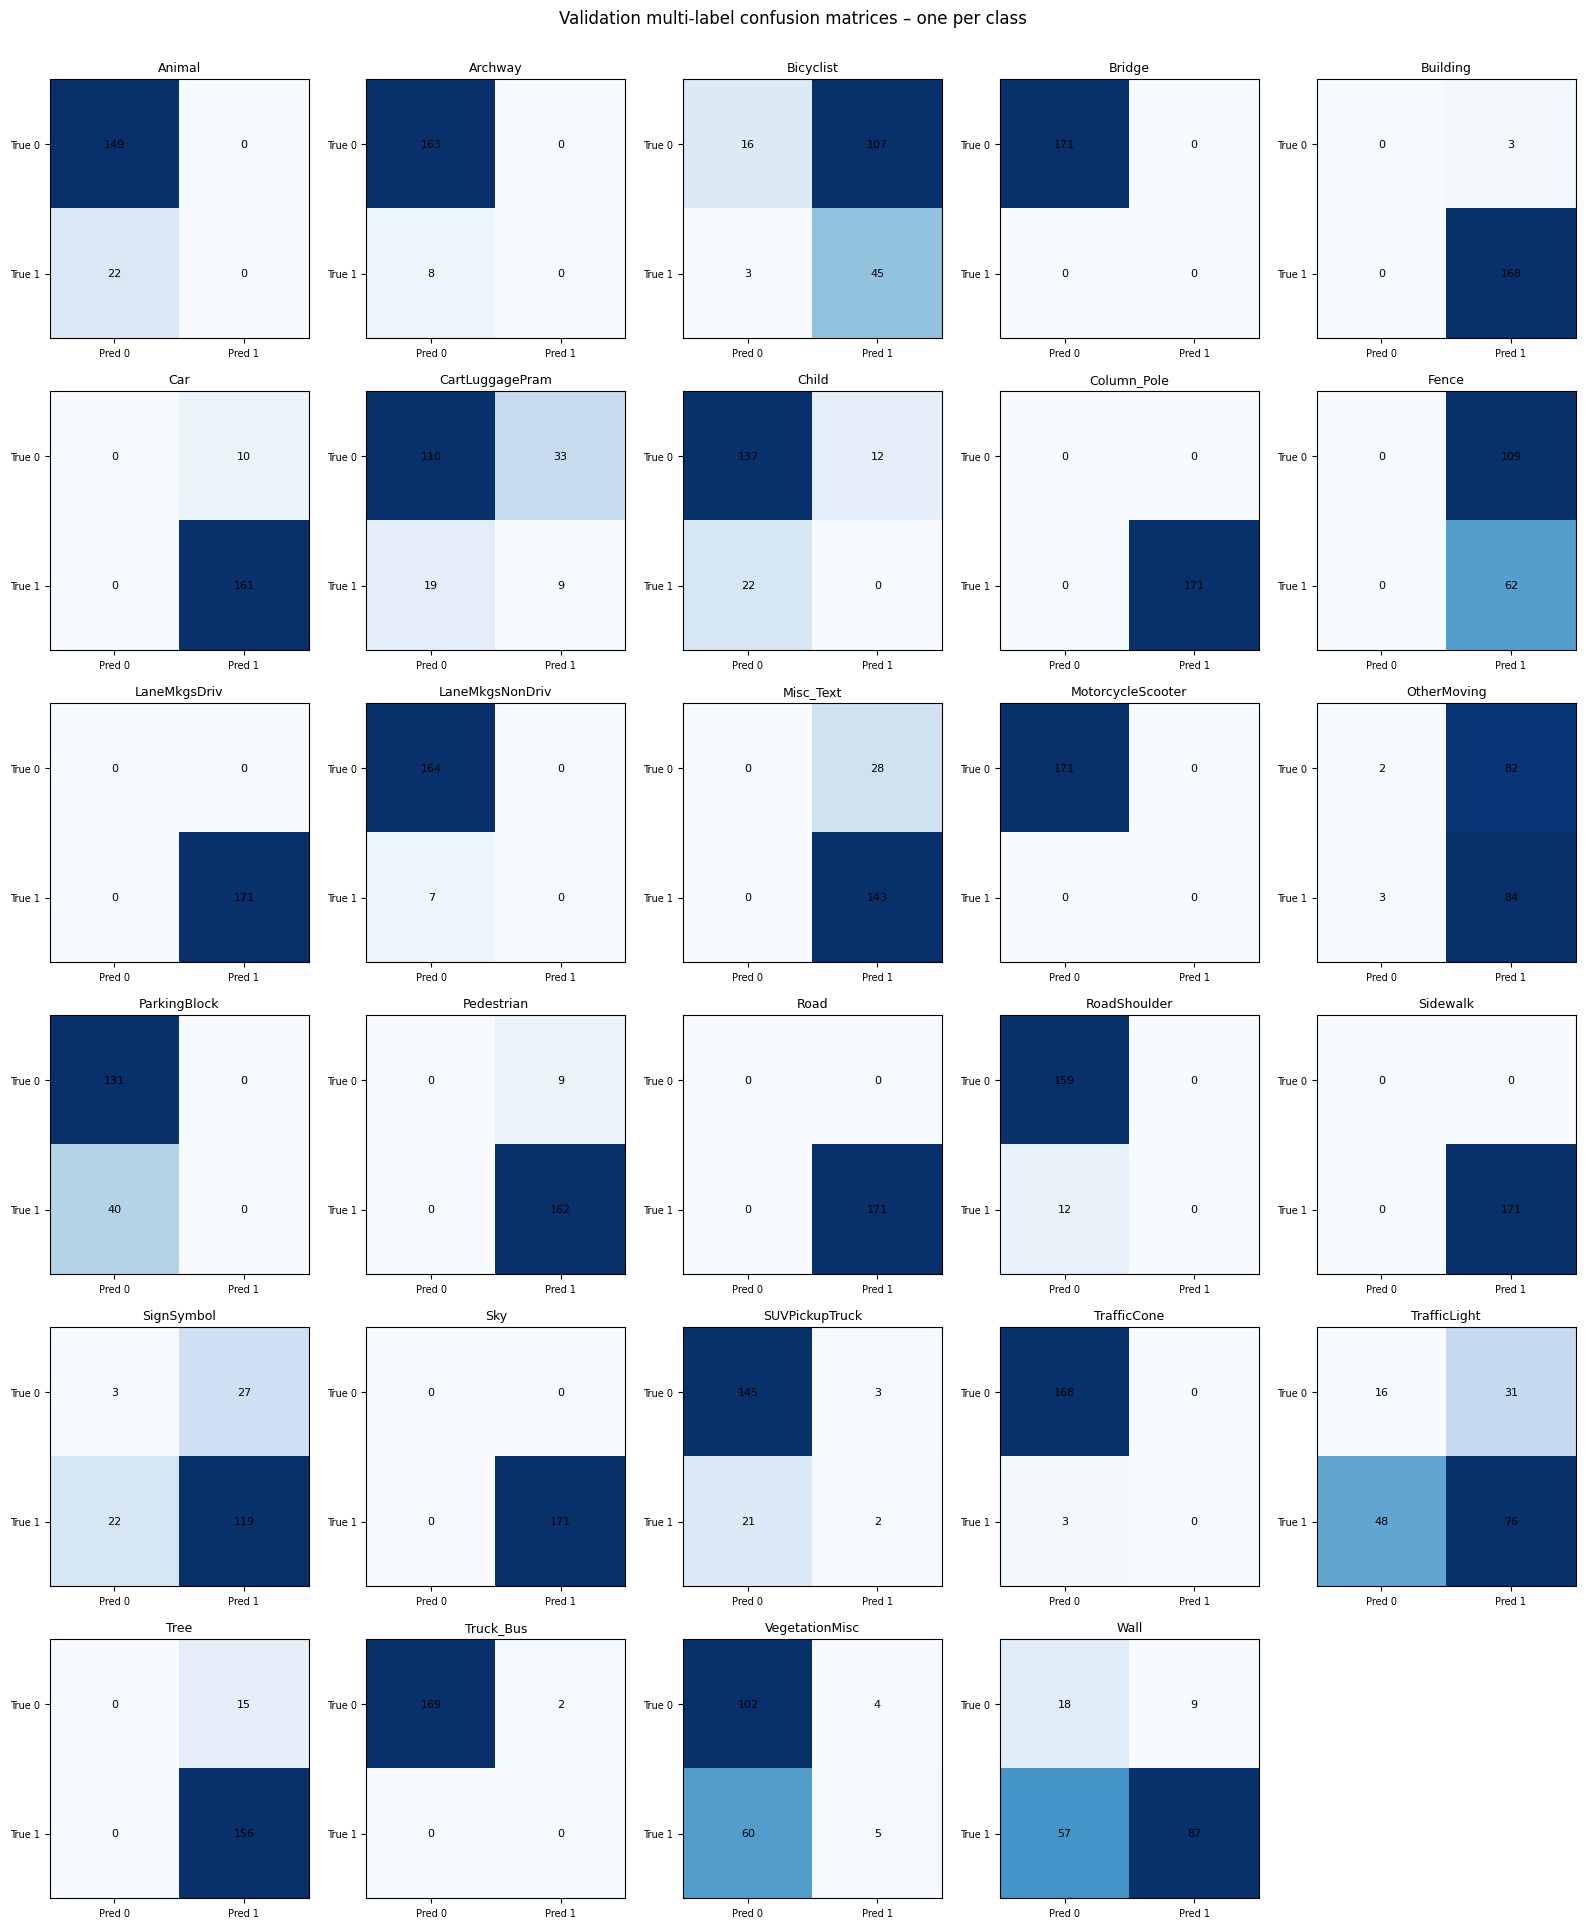

In [16]:
fig, ax = plt.subplots(figsize=(12, 8))
plot_df = val_per_class.sort_values("f1_score", ascending=True)
ax.barh(plot_df["class"], plot_df["f1_score"])
ax.set_xlim(0, 1)
ax.set_xlabel("F1 score")
ax.set_title("Validation F1 score by CamVid class")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

val_confusion_matrices = multilabel_confusion_matrix(
    y_val,
    val_predictions,
)

n_classes = len(class_columns)
n_cols = 5
n_rows = int(np.ceil(n_classes / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 3.2 * n_rows),
)
axes = np.array(axes).reshape(-1)

for index, ax in enumerate(axes):
    if index >= n_classes:
        ax.axis("off")
        continue

    matrix = val_confusion_matrices[index]
    ax.imshow(matrix, cmap="Blues")
    ax.set_title(class_columns[index], fontsize=9)
    ax.set_xticks([0, 1], labels=["Pred 0", "Pred 1"], fontsize=7)
    ax.set_yticks([0, 1], labels=["True 0", "True 1"], fontsize=7)

    for row_index in range(2):
        for col_index in range(2):
            ax.text(
                col_index,
                row_index,
                str(matrix[row_index, col_index]),
                ha="center",
                va="center",
                fontsize=8,
            )

fig.suptitle(
    "Validation multi-label confusion matrices – one per class",
    y=1.002,
)
plt.tight_layout()
plt.show()

## 16. Final held-out test evaluation

Reload the fine-tuning checkpoint with the lowest validation loss, then evaluate the test partition once. Do not tune the threshold or model based on test results if the goal is an unbiased final evaluation.

In [17]:
best_checkpoint = OUTPUT_DIR / "best_finetune.pth"

if not best_checkpoint.is_file():
    raise FileNotFoundError(
        f"Fine-tuning checkpoint not found: {best_checkpoint.resolve()}"
    )

model.load_state_dict(torch.load(best_checkpoint, map_location=DEVICE))
model.eval()

y_test, test_probabilities, test_filenames = predict_loader(model, test_loader)

test_summary, test_per_class, test_predictions = calculate_multilabel_metrics(
    y_test,
    test_probabilities,
)

print("Held-out test summary (threshold = 0.5)")
display(pd.DataFrame([test_summary]).T.rename(columns={0: "test"}))
display(test_per_class)

test_per_class.to_csv(
    OUTPUT_DIR / "test_per_class_metrics.csv",
    index=False,
)
with open(OUTPUT_DIR / "test_summary_metrics.json", "w") as file:
    json.dump(test_summary, file, indent=2)

Held-out test summary (threshold = 0.5)


,test
threshold,0.500000
micro_precision,0.806768
micro_recall,0.849251
micro_f1,0.827465
macro_precision,0.524018
macro_recall,0.557665
macro_f1,0.515303
weighted_precision,0.836426
weighted_recall,0.849251
weighted_f1,0.813408


,class,precision,recall,f1_score,support
4,Building,1.000000,1.000000,1.000000,124
5,Car,1.000000,1.000000,1.000000,124
19,Sidewalk,1.000000,1.000000,1.000000,124
17,Road,1.000000,1.000000,1.000000,124
8,Column_Pole,0.991935,1.000000,0.995951,123
21,Sky,0.991935,1.000000,0.995951,123
25,Tree,1.000000,0.991935,0.995951,124
10,LaneMkgsDriv,0.991935,1.000000,0.995951,123
16,Pedestrian,0.959677,1.000000,0.979424,119
24,TrafficLight,0.869919,1.000000,0.930435,107


## 17. Test classification report and sample predictions

The classification report provides class-wise precision, recall and F1. The sample predictions provide a qualitative check of the multi-label outputs. These are image-level class-presence predictions.

                   precision    recall  f1-score   support

           Animal       0.00      0.00      0.00         0
          Archway       0.00      0.00      0.00         0
        Bicyclist       0.60      0.96      0.73        75
           Bridge       0.00      0.00      0.00         0
         Building       1.00      1.00      1.00       124
              Car       1.00      1.00      1.00       124
  CartLuggagePram       0.33      0.03      0.06        59
            Child       0.00      0.00      0.00         0
      Column_Pole       0.99      1.00      1.00       123
            Fence       0.33      1.00      0.50        41
     LaneMkgsDriv       0.99      1.00      1.00       123
  LaneMkgsNonDriv       0.00      0.00      0.00         0
        Misc_Text       0.82      1.00      0.90       102
MotorcycleScooter       0.00      0.00      0.00         0
      OtherMoving       0.54      1.00      0.70        67
     ParkingBlock       0.00      0.00      0.00       

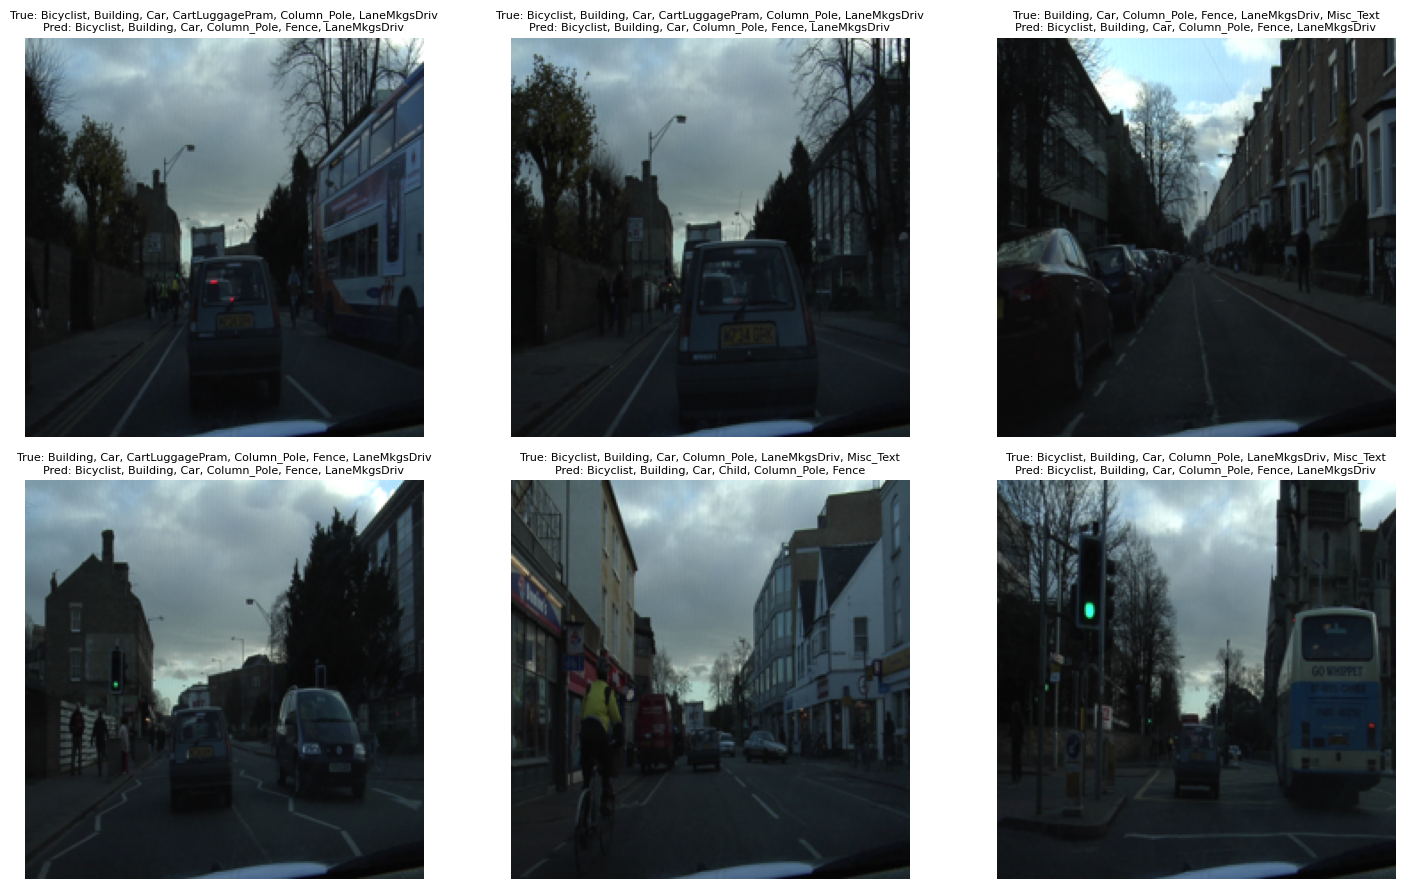

In [18]:
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=class_columns,
        zero_division=0,
    )
)

rng = np.random.default_rng(SEED)
sample_count = min(6, len(test_filenames))
sample_indices = rng.choice(
    len(test_filenames),
    size=sample_count,
    replace=False,
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, index in zip(axes.flat, sample_indices):
    row = test_df.iloc[index]

    with Image.open(row["resolved_image_path"]) as img:
        display_image = img.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))

    true_labels = [
        class_columns[j]
        for j in range(len(class_columns))
        if y_test[index, j] == 1
    ]
    predicted_labels = [
        class_columns[j]
        for j in range(len(class_columns))
        if test_predictions[index, j] == 1
    ]

    ax.imshow(display_image)
    ax.set_title(
        f"True: {', '.join(true_labels[:6])}\n"
        f"Pred: {', '.join(predicted_labels[:6])}",
        fontsize=8,
    )
    ax.axis("off")

for ax in axes.flat[sample_count:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 18. Save model and experiment artifacts

The saved configuration includes the exact 29-class order. Preserve this order when loading the model for inference; output index `i` corresponds to `class_columns[i]`.

In [19]:
artifact_config = {
    "model_name": "ResNet-18",
    "task": "CamVid multi-label image classification",
    "pretrained_imagenet": bool(USE_IMAGENET_WEIGHTS),
    "class_columns": class_columns,
    "excluded_zero_support_classes": zero_support_classes,
    "image_size": IMAGE_SIZE,
    "threshold": THRESHOLD,
    "imagenet_mean": imagenet_mean,
    "imagenet_std": imagenet_std,
    "seed": SEED,
    "metadata_file": str(METADATA_PATH),
    "split_counts": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "test": int(len(test_df)),
    },
    "best_validation_loss_head": float(best_head_val_loss),
    "best_validation_loss_finetune": float(best_finetune_val_loss),
    "validation_metrics": val_summary,
    "test_metrics": test_summary,
}

torch.save(
    model.state_dict(),
    OUTPUT_DIR / "resnet18_camvid_multilabel.pth",
)

with open(OUTPUT_DIR / "model_config_and_metrics.json", "w") as file:
    json.dump(artifact_config, file, indent=2)

print("Saved artifacts:")
for artifact_path in sorted(OUTPUT_DIR.iterdir()):
    print(artifact_path.name, f"({artifact_path.stat().st_size:,} bytes)")

Saved artifacts:
best_finetune.pth (44,845,579 bytes)
best_head.pth (44,845,067 bytes)
model_config_and_metrics.json (2,181 bytes)
resnet18_camvid_multilabel.pth (44,847,371 bytes)
test_per_class_metrics.csv (1,296 bytes)
test_summary_metrics.json (440 bytes)
training_history.csv (757 bytes)
validation_per_class_metrics.csv (1,256 bytes)
validation_summary_metrics.json (456 bytes)


## 19. Compare with Notebook 04 baseline CNN

Enter the actual **held-out test metrics** from Notebook 04. Ensure that Notebook 04 and Notebook 07 use the same 29 target classes, the same class order, and the same test partition (124 images).

Do not enter validation metrics here. If Notebook 04 used a different class set or split, report the experiments separately rather than presenting a direct comparison.

In [20]:
# Replace np.nan with the actual Notebook 04 TEST metrics.
baseline_test_metrics = {
    "micro_f1": np.nan,
    "macro_f1": np.nan,
    "exact_match_accuracy": np.nan,
    "hamming_loss": np.nan,
}

comparison_rows = []
for metric_name, baseline_value in baseline_test_metrics.items():
    comparison_rows.append({
        "metric": metric_name,
        "Notebook 04 baseline CNN": baseline_value,
        "Notebook 07 ResNet-18": test_summary[metric_name],
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

if comparison_df["Notebook 04 baseline CNN"].notna().all():
    comparison_df["difference (ResNet-18 minus baseline)"] = (
        comparison_df["Notebook 07 ResNet-18"]
        - comparison_df["Notebook 04 baseline CNN"]
    )
    display(comparison_df)
else:
    print(
        "Enter the actual Notebook 04 held-out test metrics to complete "
        "the quantitative comparison."
    )

,metric,Notebook 04 baseline CNN,Notebook 07 ResNet-18
0,micro_f1,NaN,0.827465
1,macro_f1,NaN,0.515303
2,exact_match_accuracy,NaN,0.000000
3,hamming_loss,NaN,0.190768


Enter the actual Notebook 04 held-out test metrics to complete the quantitative comparison.


## 20. Interpretation and conclusion

Complete this section after reviewing the observed training curves, validation metrics, test metrics and per-class results.

Address the following questions:

1. Did ImageNet-pretrained ResNet-18 outperform the baseline CNN on the held-out test set?
2. Did transfer learning improve macro F1, particularly for less frequent classes?
3. Which classes achieved the strongest and weakest F1 scores?
4. Is there evidence of overfitting from the training and validation loss curves?
5. Which classes are frequently confused, based on the per-class confusion matrices?
6. What are the limitations of using image-level class-presence labels derived from CamVid semantic masks?

### Important interpretation note

`Train` and `Tunnel` were excluded because their image-level labels are zero for all 701 records. The model cannot learn a class for which the supplied metadata contains no positive examples. This is a limitation of the available dataset labels, not evidence that those classes never occur in real road scenes.

## 21. Reproducibility and completion checklist

- [ ] `METADATA_PATH` points to `preprocessed/camvid_preprocessed_metadata.csv`.
- [ ] Image paths resolve to the original CamVid image files.
- [ ] The master metadata contains 701 unique image records.
- [ ] The retained split counts are 406 train, 171 validation and 124 test.
- [ ] The 31 candidate class columns were detected.
- [ ] `Train` and `Tunnel` were excluded due to zero positive examples.
- [ ] Exactly 29 supported class targets were used.
- [ ] The sequence-level split integrity check passed.
- [ ] Both training stages completed and the best fine-tuning checkpoint was saved.
- [ ] Validation and held-out test metrics were generated.
- [ ] Notebook 04 test metrics were entered only after confirming identical labels and test split.
- [ ] The interpretation and conclusion section was completed.

**Expected deliverables:** trained ResNet-18 weights, model configuration, training history, validation/test summary metrics, per-class metrics, and qualitative sample predictions.